# EGBE: modelling the evolution gravel-sized alluvium layer and the underlying bedrock in a network of rivers

### This notebook provides a brief introduction and user’s guide to the Extended Gravel Bed Eroder (EGBE) and SoilGrading Landlab components. 

# EGBE Model description
EGBE simulates drainage network evolution for a network of rivers that have a layer of gravel alluvium overlying bedrock, taking into account heterogeneous sizes OR hardness of the gravels. EGBE relies on an additional Landlab components that handle flow routing (for exampple FlowAccumulator) and track the mass of hetrogenoues sediment layer (SoilGrading).
EGBE is an advanced version of the Gravel Bedrock Eroder model (GBE) decribed in the following publication:

* Gabel, V., Tucker, G. E., & Campforts, B. (2024). A mathematical model for bedrock incision in near‐threshold gravel‐bed rivers. Earth Surface Processes and Landforms, 49(13), 4168-4186.

## Input parameters
* grid : ModelGrid
    A Landlab model grid object
* intermittency_factor : float (default 0.01)
    Fraction of time that bankfull flow occurs
* sediment_porosity : float (default 0.35)
    Bulk porosity of bed sediment
* depth_decay_scale : float (default 1.0)
    Scale for depth decay in bedrock exposure function
* plucking_coefficient : float or (n_core_nodes,) array of float (default 1.0e-4 1/m)
    Rate coefficient for bedrock erosion by plucking
* epsilon : float (default 0.2)
    Near-threshold coefficient
* abrasion_coefficient : float (default 0.0 1/m) *DEPRECATED*
    Abrasion coefficient with units of inverse length
* bedrock_abrasion_coefficients : float (default 0)
    Abrasion coefficient for bedrock
* fractions_from_plucking : float (default 1)
    The mass fraction that is plucked from the bedrock for each sediment class
* rho_sed : float (default 2650)
    Density of the alluvial layer
* rho_water : float (default 1000)
    Density of the fluid
* use_fixed_width: Boolean (default True)
    Flag that if set to true, EGBE run under fixed-width model. If set to false,
    EGBE run under dynamic-width model (default true).
* width_coeff : float (default 0.002)
    Empirical coefficient for channel width;
    NOTE: units, if exponent is 1/2: 1/(m^0.5*s^0.5) -- need to make this conversion to years, not seconds
* width_expt : float (default 0.5)
    Empirical exponent for channel width;
* mannings_n : float (default 0.05)
    Manning's roughness coeffcient
* tau_star_c_median : float (default 0.045)
    Dimensionless critical shear stress for transport of median grain size
* alpha : float (default 0.68)
    Empirical exponent for critical shear stress
* tau_c_bedrock : float (default 10)
    Critical shear stress for bedrock plucking
* d_min : float (default 0.1)
    Immobile depth of alluvial layer
* plucking_by_tools_flag : Boolean (default False)
    A flag



## Model fields

Below are listed fields updated by the component at the grid locations. Other fields handled by other Landlab components, used by EGBE but that are not updated by it are: `flow__link_to_receiver_node`, `flow__receiver_node`, `flow__upstream_node_order`, `surface_water__discharge`, `topographic__steepest_slope`


* `bedrock__elevation` [m]: elevation of the bedrock surface
* `soil__depth` [m]: Depth of soil or weathered bedrock
* `topographic__elevation` [m]: Land surface topographic elevation
* `grains__weight` [$kg/m^{2}$]: Mass per unit area of grains in each size class stored at node
* `bedload_sediment__rate_of_loss_to_abrasion` [m/y]: Rate of bedload sediment volume loss to abrasion per unit area
* `bedload_sediment__volume_influx` [$m^{3}/y$]: Volumetric incoming streamwise bedload sediment transport rate
* `bedload_sediment__volume_outflux`[$m^{3}/y$]: Volumetric outgoing streamwise bedload sediment transport rate
* `bedrock__abrasion_rate` [m/y]: rate of bedrock lowering by abrasion
* `bedrock__exposure_fraction`[-]: fractional exposure of bedrock
* `bedrock__plucking_rate` [m/y]: rate of bedrock lowering by plucking
* `bedrock__lowering_rate` [m/y]: Rate of lowering of bedrock surface
* `sediment__rate_of_change` [m/y]: Time rate of change of sediment thickness

# Background on SoilGrading component

SoilGrading component track sediment mass of diffrent classes and simulates their grading/fragmentation due to weathering based on the mARM (Cohen et al., 2009, 2010) model. The fragmentation process is controlled by a weathering transition matrix which defines the relative mass change in each soil grain size class (grading class) as a result of the fracturing of particles in the weathering mechanism.

Publications:
*   Cohen, S., Willgoose, G., & Hancock, G. (2009). The mARM spatially distributed soil
    evolution model: A computationally efficient modeling framework and analysis of
    hillslope soil surface organization. Journal of Geophysical Research: Earth Surface,
    114(F3).

*   Cohen, S., Willgoose, G., & Hancock, G. (2010). The mARM3D spatially distributed
    soil evolution model: Three‐dimensional model framework and analysis of hillslope
    and landform responses. Journal of Geophysical Research: Earth Surface, 115(F4).

## Input parameters
* grid : ModelGrid
* meansizes : float (m)
    The mean grain size in each size class.
    Can be provided as list or tuple.
* limits : float (m)
    2D array with the limits of each size class
* fragmentation_pattern : float (-)
    A list of floats describes how much mass transfer from a parent grain to
    daughters.
* A_factor : float (-. 0-1), optional
    Factor that control the fragmentation rate.
* initial_median_size : float (m), optional
    The initial median grain size in the soil.
* grains_weight : float (kg/m^2), optional
    The weight per unit area of each grain size class.
* soil_density : float (kg/m^3), optional
    Density of the soil particles.
* phi : float (-. 0-1), optional
    Soil porosity.
* initial_total_soil_weight : float (kg/m^2), optional
    The total initial soil weight per unit area (taking into account all grain size classes).
* std: float, optional
    The standard deviation of grain size distribution.
* CV: float, optional
    Coefficient of variance of the grain size distribution.
* is_bedrock_distribution_flag: bool, optional
    A flag to indicate if the grain size distribution is generated for soil or
    bedrock layer.
* interpolate_median_size: bool, optional
    Flag to indicate if median size is to be determined using linear interpolation within
    size classes
* seed: float, optional
    Provide seed to set grain size distribution.
    If not provided, seed is set to 2024.

## Model fields
* `bedrock__elevation` [m]: elevation of the bedrock surface
* `soil__depth` [m]: Depth of soil or weathered bedrock
* `topographic__elevation` [m]: Land surface topographic elevation
* `grains__weight` [$kg/m^{2}$]: Mass per unit area of grains in each size class stored at node
* `median_size__weight` [m]: The median grain size in each node based on soil grains weight distribution
* `grains_classes__size` [m]: The size of each grain size class
* `bed_grains__proportions` [-]: Proportional weight of each grain size class in the bed layer

# Import required libraries and landlab components
Required libraries are Landlab components that used to create grids, flow accumulation and simulate fluvial and landslide erosoin. Python library for plotting and scientific computations are matplotlib, respectively

In [1]:
from landlab.components import ExtendedGravelBedrockEroder
from landlab.components.soil_grading import SoilGrading
from landlab.components import PriorityFloodFlowRouter, FlowAccumulator
from landlab import RasterModelGrid, HexModelGrid
import matplotlib.pyplot as plt
from landlab.components import BedrockLandslider
import numpy as np
from landlab import imshow_grid
from landlab.components import ChannelProfiler

### As this notebook will demonstrate various features of the ExtendedGravelBedrockEroder, let's create three functions that will be used several times in the notebook: 
* (1) `create_1d_grid` and `create_2d_grid` creates 1/2D grids and set initial and boundary conditions
* (2) `init_components` initializes the components associated with the grid
* (3) `plot the results` helps us to visualize the results


The `create_1d_grid` procedure generates a synthetic Raser grid with 3 columns and sets the perimeter nodes  as boundary nodes such that the flow direction is in only 1 dimension in space. The procedure `create_2d_grid` creates either a Raser or a Hex model grid while the flow is in 2 spatial dimensions. In all cases, the domain starts with random topographic roughness to force flow convergence and channelization.

Also, once the grid has been created, several key fields are added to the grid (among others): 
* `soil__depth`: the soil depth [m] at node
* `grains__weight`: mass per node area of each sediment class [kg/m2]
* `bedrock__elevation`: elevation of the rock layer [m]
* `topographic__elevation`: the topographic elevation [m]

In [2]:
def create_1d_grid(n_rows=62,
                   n_cols=3,
                   spacing=5000,
                   init_slope=0.001):
        
    grid = RasterModelGrid((n_rows, n_cols), xy_spacing=spacing)
    # Create fields
    topo = grid.add_zeros('topographic__elevation', at='node')
    rock_elev = grid.add_zeros('bedrock__elevation', at='node')
    soil_depth = grid.add_zeros('soil__depth', at='node')
    
    # Set boundaries and initial topography
    grid.set_watershed_boundary_condition_outlet_id(grid.nodes[0, 1],'topographic__elevation')
    rock_elev[:] += grid.y_of_node * init_slope 

    return grid, topo, rock_elev,  soil_depth



def create_2d_grid(n_rows=50,
                   n_cols=50,
                   spacing=5000,
                   init_slope=0.001,
                  hex_grid =True):
                   # Create grid

    if hex_grid:
        grid = HexModelGrid((n_rows, n_cols),
                            spacing=spacing,
                            node_layout="rect")
        grid.status_at_node[grid.nodes_at_left_edge]=grid.BC_NODE_IS_CLOSED
        grid.status_at_node[grid.nodes_at_right_edge]=grid.BC_NODE_IS_CLOSED
        grid.status_at_node[grid.nodes_at_top_edge]=grid.BC_NODE_IS_CLOSED
        grid.status_at_node[grid.nodes_at_bottom_edge] = grid.BC_NODE_IS_FIXED_VALUE
    else:
        grid = RasterModelGrid((n_rows, n_cols), xy_spacing=spacing)
        grid.set_closed_boundaries_at_grid_edges(right=True, top=True, left=True, bottom=False)
        
    # Create fields
    topo = grid.add_zeros('topographic__elevation', at='node')
    rock_elev = grid.add_zeros('bedrock__elevation', at='node')
    soil_depth = grid.add_zeros('soil__depth', at='node')
    
    # Set boundaries and initial topography
    rock_elev[:] += grid.y_of_node * init_slope
    topo[:] = soil_depth[:] + rock_elev[:]
    
    return grid, topo, rock_elev,  soil_depth

In [3]:
def init_components(grid,
                    meansizes = 0.03,
                    grains_weight = 0,
                    phi = 0.4,
                    sediment_density = 2650,
                    bed_grains_proportions = 1,
                    runoff_rate = 5.0,
                    intermittency_factor = 0.1,
                    depth_decay_scale = 1,
                    plucking_coefficient = 1,
                    abrasion_coefficients = 0,
                    bedrock_abrasion_coefficient = 0,
                    rho_water = 1000,
                    use_fixed_width = True,
                    fixed_width_coeff = 0.002,
                    fixed_width_expt = 0.5,
                    mannings_n = 0.05,
                    tau_star_c_median = 0.045,
                    alpha = 0.68,
                    tau_c_bedrock = 10,
                    d_min = 0.1,
                    plucking_by_tools_flag = False,
                    angle_int_frict=0.01,
                    cohesion_eff=1e2,
                    landslides_return_time=1,
                    landslides_on_boundary_nodes=False,
                    min_deposition_slope = 0.005,
                    threshold_slope=0.1,
                    init_hylands=False):



    sg = SoilGrading(grid,
                     meansizes=meansizes,
                     grains_weight=grains_weight,
                     phi=phi,
                     soil_density=sediment_density)
    sg.update_bed_grains_proportions(proportions=bed_grains_proportions)


    if init_hylands:
        print('hyland is on')
        fa = PriorityFloodFlowRouter(grid,
                                 surface="topographic__elevation",
                                 accumulate_flow=True,
                                 runoff_rate=runoff_rate,
                                 flow_metric='D8',
                                 update_flow_depressions=True,
                                 depression_handler='fill',
                                 epsilon=True,
                                     separate_hill_flow=True)
    else:

        if isinstance(grid,HexModelGrid):
            flow_director='FlowDirectorSteepest'
        else:
            flow_director='D8'
        fa = FlowAccumulator(grid,surface="topographic__elevation",
                             runoff_rate=runoff_rate,
                             depression_finder="DepressionFinderAndRouter",
                             flow_director=flow_director)


    
    # Init eroder
    eroder = ExtendedGravelBedrockEroder(grid,
                                         intermittency_factor=intermittency_factor,
                                         sediment_porosity=phi,
                                         depth_decay_scale=depth_decay_scale ,
                                         plucking_coefficient=plucking_coefficient,
                                         abrasion_coefficients=abrasion_coefficients,
                                         bedrock_abrasion_coefficient=bedrock_abrasion_coefficient,
                                         fractions_from_plucking=bed_grains_proportions,
                                         rho_sed=sediment_density,
                                         rho_water=rho_water,
                                         use_fixed_width=use_fixed_width,
                                         fixed_width_coeff=fixed_width_coeff,
                                         fixed_width_expt=fixed_width_expt,
                                         mannings_n=mannings_n,
                                         tau_star_c_median=tau_star_c_median,
                                         alpha=alpha,
                                         tau_c_bedrock=tau_c_bedrock,
                                         d_min=d_min,
                                         plucking_by_tools_flag=plucking_by_tools_flag
                                         )
    
    hy=init_hylands
    if init_hylands:

        hy = BedrockLandslider(
            grid,
            angle_int_frict=angle_int_frict,
            cohesion_eff=cohesion_eff,
            landslides_return_time=landslides_return_time,
            rho_r = sediment_density,
            phi = phi,
            landslides_on_boundary_nodes=landslides_on_boundary_nodes,
            min_deposition_slope=min_deposition_slope,
            threshold_slope=threshold_slope)


    return grid, sg, fa, eroder, hy

The procedure `plot_profile` will generate an elevation profile and slope-area diagram plots

In [4]:
def plot_profile(ax, grid, color='black',
                sqrmeter_to_sqrkm=True,
                convert_m_to_km=True,
                label = ''):

    xvec = grid.y_of_node[grid.core_nodes]
    if convert_m_to_km:
        xvec /= 1000
    ax[0].plot(xvec, grid.at_node['topographic__elevation'][grid1.core_nodes],color=color,
              label=label)
    
    ax[0].set_xlabel('Distance upstream [km]')
    ax[0].set_ylabel('Elevation [m]')


    if sqrmeter_to_sqrkm:
        a_factor =1000**2
    else:
        a_factor=1
        
    plt.axes(ax[1])
    plt.loglog(
        grid.at_node["drainage_area"][grid.core_nodes]/a_factor,
        grid.at_node["topographic__steepest_slope"][grid.core_nodes],
        ".",
        color=color,
        lw=2,label=label
    )
    
    ax[1].set_ylabel('Slope [m/m]')
    ax[1].set_xlabel('Area [$m^{2}$]')

# Example 1: High versus low sediment attrition
In this example, we initialize two 1D grids that represent 60 km river profiles with a grid spacing of 500 m. In each grid, only one node is set as an open boundary (domain outlet), and the initial topography is a low-inclined slope. The topography evolves under a constant rock uplift rate and the action of fluvial transport and incision using the EGBE component. All else being equal, one model is set with charectristics sediment attrition length that is much shorter than the river length (sediments are very soft; 10 km), while the other with sediment attrition characteristic length that is longer than the river length (hard sediments; 100 km). Sediments are assumed to be homogenous in size (cobble, 6 cm).

In [5]:
grid1, topo1, rock_elev1,  soil_depth1 =  create_1d_grid()
grid2, topo2, rock_elev2,  soil_depth2 =  create_1d_grid()

abrasion_coefficients1 = 10**-4
abrasion_coefficients2 = 10**-5

grid1, sg1, fa1, eroder1, hy1 = init_components(grid1, meansizes=0.06, abrasion_coefficients=abrasion_coefficients1)
grid2, sg2, fa2, eroder2, hy2 = init_components(grid2, meansizes=0.06, abrasion_coefficients = abrasion_coefficients2)

/Users/yuvalshmilovitz/Dropbox/Mac/Documents/git_folders/ys-sm-gt/gbe_extended/src/landlab/graph/sort/sort.py:724: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  angle_of_spoke_at_hub = np.arctan2(dy, dx, where=spokes_at_hub != -1)


## Run the main model loop to evolve the river profiles
EGBE component calculates sediment transport, attrition and bedrock erosion through plucking and abrasion. The following main loop iterates in constant time steps until the elapsed time reaches a user-defined run time. While the user can set the maximal timestep, EGBE may run in musch smaller increaments to ensure numerical stability.

The main steps of the loop are:
* Flow routing component determine topographic slopes and water discharge at all nodes on the model domain
* EGBE computes topographic, soil, and bedrock elevation changes
* Bedrock and topographic elevation are updated according to the uplift rate.

In [6]:
uplift_rate = 10**-3
timestep=150
total_time = int(3.5e6)
for i in range(0,total_time,timestep):

    fa1.run_one_step()
    eroder1.run_one_step(1*timestep)
    grid1.at_node['bedrock__elevation'][grid1.core_nodes]+=uplift_rate*timestep

    fa2.run_one_step()
    eroder2.run_one_step(1*timestep)
    grid2.at_node['bedrock__elevation'][grid2.core_nodes]+=uplift_rate*timestep
    
    if np.mod(i,1e5)==0:
        print(np.round((i/total_time)*100,1), '% completed')
print(np.round((i/total_time)*100,1), '% completed')

0.0 % completed
8.6 % completed
17.1 % completed
25.7 % completed
34.3 % completed
42.9 % completed
51.4 % completed
60.0 % completed
68.6 % completed
77.1 % completed
85.7 % completed
94.3 % completed
100.0 % completed


## Results visualization
Lets use our pre-defined function for plotting (`plot_profile`) to see how the rivers' topographic profile and slope-area relations are look like

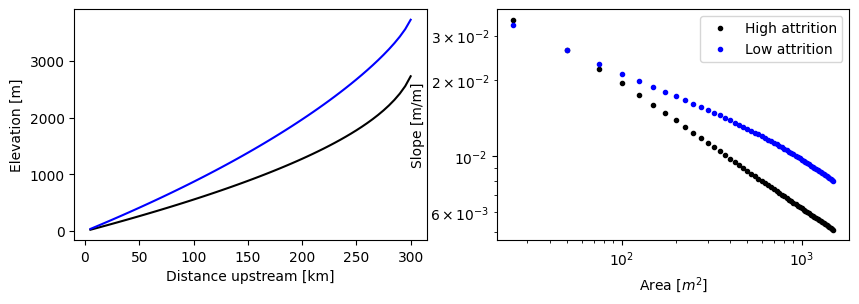

In [7]:
fig,ax = plt.subplots(1,2,figsize=(10,3))
plot_profile(ax, grid1, color='black',label='High attrition')
plot_profile(ax, grid2, color='blue', label= 'Low attrition')
plt.legend()
plt.show()

# Example 2: The role of bedrock abrasions
Lets initialize two similar 1D model grids to the previous example. However, in this case, the models differ in the rate at which the bedrock is eroded due to the action of sediment abrasion and in the sediment hardness.  In the first mode, `grid1`, the sediments are much softer than the bedrock, while in `grid2`, the sediments are much harder than the bedrock. 

In [8]:
# Run two EGBE models with two diffrent bedrock abrasion coeffs
grid1, topo1, rock_elev1,  soil_depth1 =  create_1d_grid()
grid2, topo2, rock_elev2,  soil_depth2 =  create_1d_grid()

abrasion_coefficients1 = 10**-3
abrasion_coefficients2 = 10**-6

grid1, sg1, fa1, eroder1, hy1 = init_components(grid1,
                                                abrasion_coefficients=abrasion_coefficients1,
                                                bedrock_abrasion_coefficient=abrasion_coefficients2)

                                                
grid2, sg2, fa2, eroder2, hy2 = init_components(grid2,
                                                abrasion_coefficients = abrasion_coefficients2,
                                                bedrock_abrasion_coefficient=abrasion_coefficients1)

In [9]:
uplift_rate = 10**-3
timestep=250
total_time = int(2e6)
for i in range(0,total_time,timestep):

    fa1.run_one_step()
    eroder1.run_one_step(1*timestep)
    grid1.at_node['bedrock__elevation'][grid1.core_nodes]+=uplift_rate*timestep

    fa2.run_one_step()
    eroder2.run_one_step(1*timestep)
    grid2.at_node['bedrock__elevation'][grid2.core_nodes]+=uplift_rate*timestep
    
    if np.mod(i,5e5)==0:
        print(np.round((i/total_time)*100,1), '% completed')
print(np.round((i/total_time)*100,1), '% completed')

0.0 % completed
25.0 % completed
50.0 % completed
75.0 % completed
100.0 % completed


## Plot the results

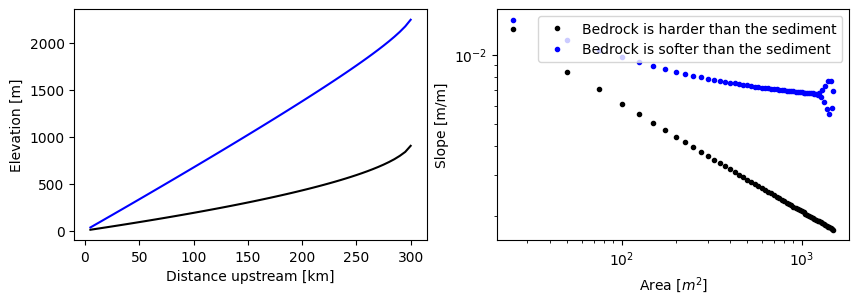

In [10]:
fig,ax = plt.subplots(1,2,figsize=(10,3))
plot_profile(ax, grid1, color='black',label= 'Bedrock is harder than the sediment')
plot_profile(ax, grid2, color='blue', label= 'Bedrock is softer than the sediment')
plt.legend()
plt.show()

# Example 3: Fixed-width vs. Dynamic width
This example explore river profile evolution under the two assumptions regarding channel width that are allowed in EGBE: fixed-width and dynamic-width. In fixed-width mode, channel width at any given position in the channel network is calculated using an empirical power-law relationship between width and bankfull discharge. In dynamic-width mode, channel width is assumed to maintain an equilibrium state with the bankfull flow conditions that are near the threshold for mobilizing the bed sediment. With this approach,  channel width depends on bankfull discharge, slope gradient, and median grain size. 

Two models will be intialized with the same parameters. However, the first will compute channel width based on the fixed-width assumption while the other follows the near-threshold principle using dynamic-width.

In [11]:
# Fix width vs. Dynamic width
grid1, topo1, rock_elev1,  soil_depth1 =  create_1d_grid()
grid2, topo2, rock_elev2,  soil_depth2 =  create_1d_grid()

abrasion_coefficients1 = 10**(-4.3)
meansizes = 0.03

grid1, sg1, fa1, eroder1, hy1 = init_components(grid1,
                                                meansizes=meansizes,
                                                abrasion_coefficients=abrasion_coefficients1)

grid2, sg2, fa2, eroder2, hy2 = init_components(grid2,
                                                abrasion_coefficients=abrasion_coefficients1,
                                                meansizes=meansizes,
                                                use_fixed_width=False)

In [12]:
uplift_rate = 10**-3
timestep=200
total_time = int(3e6)

for i in range(0,total_time,timestep):
    fa1.run_one_step()
    eroder1.run_one_step(1*timestep)
    grid1.at_node['bedrock__elevation'][grid1.core_nodes]+=uplift_rate*timestep

    fa2.run_one_step()
    eroder2.run_one_step(1*timestep)
    grid2.at_node['bedrock__elevation'][grid2.core_nodes]+=uplift_rate*timestep
    
    if np.mod(i,5e5)==0:
        print(np.round((i/total_time)*100,1), '% completed')
print(np.round((i/total_time)*100,1), '% completed')

0.0 % completed
16.7 % completed
33.3 % completed
50.0 % completed
66.7 % completed
83.3 % completed
100.0 % completed


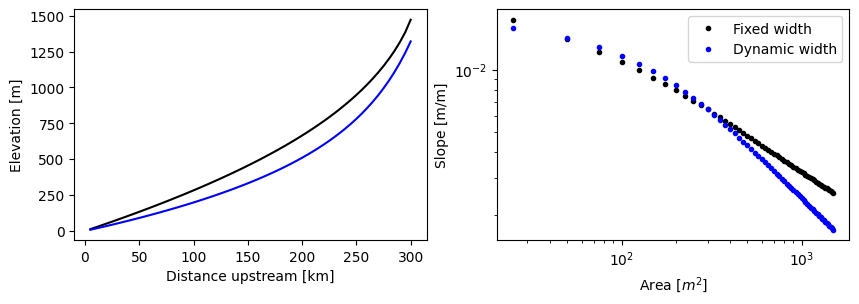

In [13]:
fig,ax = plt.subplots(1,2,figsize=(10,3))
plot_profile(ax, grid1, color='black', label='Fixed width')
plot_profile(ax, grid2, color='blue', label='Dynamic width')
plt.legend()
plt.show()

The river profile under dynamic-width is more concave relative to the fixed-width profile. We can explain this pattern by the downslope change in channel width and the shear stress exerted by the water on the river bed. 


EGBE stores these two variables, so let's plot them:

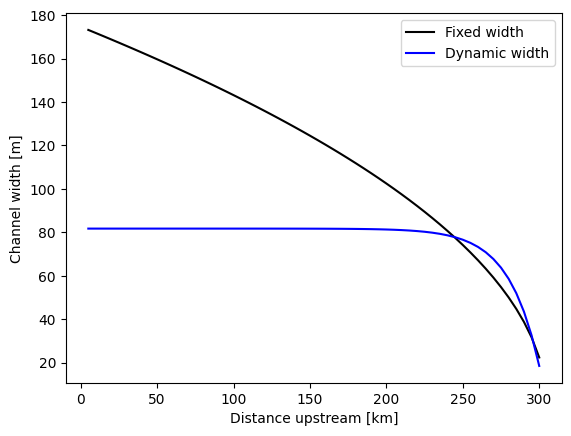

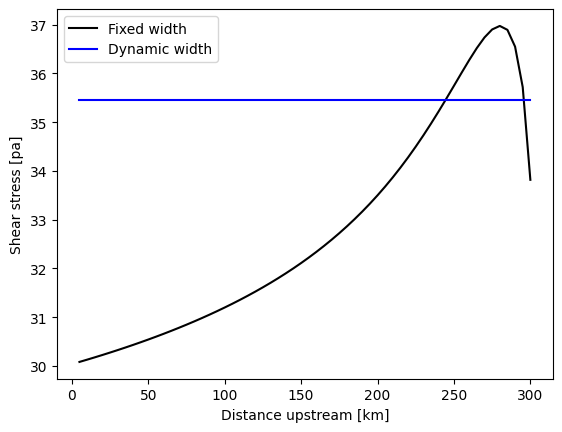

In [14]:
xvec  = grid1.node_y[grid1.core_nodes]/1000
plt.plot(xvec,eroder1._channel_width[grid1.core_nodes],color='black',label='Fixed width')
plt.plot(xvec,eroder2._channel_width[grid1.core_nodes],color='blue', label='Dynamic width')
plt.xlabel('Distance upstream [km]')
plt.ylabel('Channel width [m]')
plt.legend()
plt.show()

xvec  = grid1.node_y[grid1.core_nodes]/1000
plt.plot(xvec,eroder1._tau[grid1.core_nodes],color='black',label='Fixed width')
plt.plot(xvec,eroder2._tau[grid1.core_nodes],color='blue', label='Dynamic width')
plt.xlabel('Distance upstream [km]')
plt.ylabel('Shear stress [pa]')
plt.legend()
plt.show()


The river channel width is narrower under dynamic width in order to keep the bankfull shear stress constant (following the near-threshold principle). At a distance of ~75km from the channel head, near-trehsold stresses are higher than shear stresses under the fixed width assumption, which results in enhanced incision and lower topographic slope. 

Changes in concavity could affect the 2D structure and morphology of the river network. The next simulation will test that by running EGBE over a domain with 50 rows and 25 columns, while all  bottom nodes are set as open boundary. 

In [15]:
abrasion_coefficients1 = 10**(-4.3)
meansizes = 0.03

grid1, topo1, rock_elev1,  soil_depth1 = create_2d_grid(n_rows=50, n_cols=25)
grid1, sg1, fa1, eroder1, hy1 = init_components(grid1,
                                               meansizes=meansizes,
                                                abrasion_coefficients=abrasion_coefficients1,
                                               use_fixed_width=True)

grid2, topo2, rock_elev2,  soil_depth2 = create_2d_grid(n_rows=50, n_cols=25)
grid2, sg2, fa2, eroder2, hy2 = init_components(grid2,
                                               abrasion_coefficients=abrasion_coefficients1,
                                                meansizes=meansizes,
                                                use_fixed_width=False,)

/Users/yuvalshmilovitz/Dropbox/Mac/Documents/git_folders/ys-sm-gt/gbe_extended/src/landlab/graph/sort/sort.py:724: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  angle_of_spoke_at_hub = np.arctan2(dy, dx, where=spokes_at_hub != -1)
/Users/yuvalshmilovitz/Dropbox/Mac/Documents/git_folders/ys-sm-gt/gbe_extended/src/landlab/components/soil_grading/soil_grading.py:740: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  proportions = np.divide(
/Users/yuvalshmilovitz/Dropbox/Mac/Documents/git_folders/ys-sm-gt/gbe_extended/src/landlab/graph/sort/sort.py:724: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  angle_of_spoke_at_hub = np.arctan2(dy, dx, where=spokes_at_hub != -1)
/Users/yuvalshmilovitz/Dropbox/Mac/Documents/git_folders/ys-sm-gt/gbe_extended/src/landlab/components/soil_grading/

In [16]:
uplift_rate = 10**-3
timestep=250
total_time = int(1.5e6)

for i in range(0,total_time,timestep):
    fa1.run_one_step()
    eroder1.run_one_step(1*timestep)
    grid1.at_node['bedrock__elevation'][grid1.core_nodes]+=uplift_rate*timestep

    fa2.run_one_step()
    eroder2.run_one_step(1*timestep)
    grid2.at_node['bedrock__elevation'][grid2.core_nodes]+=uplift_rate*timestep
    
    if np.mod(i,2.5e5)==0:
        print(np.round((i/total_time)*100,1), '% completed')
print(np.round((i/total_time)*100,1), '% completed')

0.0 % completed
16.7 % completed
33.3 % completed
50.0 % completed
66.7 % completed
83.3 % completed
100.0 % completed


Using `imshow_grid` function we will generate two map-view topography figures

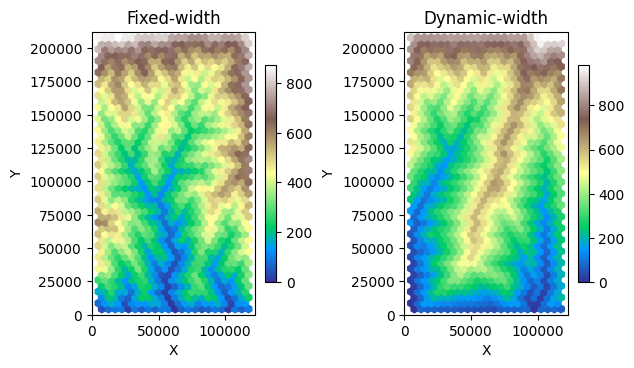

In [17]:
fig,ax = plt.subplots(1,2)
plt.axes(ax[0])
imshow_grid(grid1,'topographic__elevation',cmap='terrain', shrink=0.5)
ax[0].set_title('Fixed-width')
plt.axes(ax[1])
imshow_grid(grid2,'topographic__elevation',cmap='terrain', shrink=0.5)
ax[1].set_title('Dynamic-width')
plt.tight_layout()
plt.show()

To find and plot the channels topography in this case we will use the Landlab component `ChannelProfiler`. 

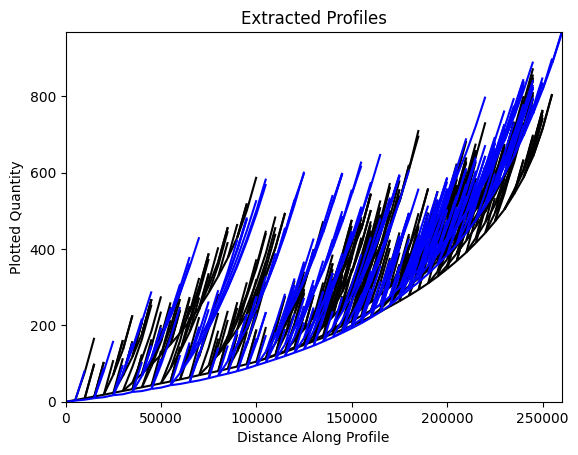

In [18]:
channel_threshold = 1e6
profiler1 = ChannelProfiler(
    grid1,
    number_of_watersheds=1,
    minimum_channel_threshold=channel_threshold,
    main_channel_only=False
)
profiler1.run_one_step()

profiler2 = ChannelProfiler(
    grid2,
    number_of_watersheds=1,
    minimum_channel_threshold=channel_threshold,
    main_channel_only=False
)
profiler2.run_one_step()

fig,ax =plt.subplots()
profiler1.plot_profiles(color='black', )
profiler2.plot_profiles(color='blue', )
plt.show()

Similar to the 1D example, this figure highlights that the dynamic-width river develops a more concave profile. Also, it shows that the dynamic-width landscape is associated with fewer tributaries, and is overall less incised.

# Example 4: Simulating river profile evolution with fine versus coarse landslide-derived sediments using EGBE and Bedrocklandslider
The Landlab BedrockLandslider (Hybrid Landscape evolution model) component computes stochastic deep-seated bedrock landsliding and landslide-derived sediment runout across two-dimensional model landscapes. To  simulates both continuous fluvial incision and sediment transport in a river associated with landslides, we will couple Bedrocklandslider with EGBE. 

## One cool application of EGBE and SoilGrading is that we can take into account the properties of the landslide grains. Here,  we will examine how the river evolves if the slide is associated with fine or coarse sediments. 

We begin by initializing two models. Their grids are associated with two sediment classes that differ in size: 1 cm and 7 cm, set by the variable `meansizes` of `SoilGrading`.  Also, in both models,  we assume the bedrock plucked into the fine fraction (1 cm) as set by the variable `bed_grains_proportions`.

In [8]:
n_rows = 200
n_cols = 3
spacing = 25
init_slope = 0.05
meansizes = [0.01, 0.07] # Two classes of diffrent size
grains_weight = [5000, 0]
bed_grains_proportions=[1,0] # Bedrock breaks only into the smaller class
phi = 0.4
sediment_density = 2650
runoff_rate=5
elev_jump = 150


grid1, topo1, rock_elev1,  soil_depth1 =  create_1d_grid(n_rows = n_rows, init_slope=init_slope, spacing=spacing)
grid2, topo2, rock_elev2,  soil_depth2 =  create_1d_grid(n_rows = n_rows, init_slope=init_slope, spacing=spacing)

grid1, sg1, fa1, eroder1, hy1 = init_components(grid1,
                                                bed_grains_proportions=bed_grains_proportions,
                                                meansizes=meansizes,
                                               init_hylands = True,
                                               threshold_slope=0.5,
                                               angle_int_frict=0.5,
                                                min_deposition_slope=0.2,
                                                runoff_rate=runoff_rate,
                                               grains_weight=grains_weight)

grid2, sg2, fa2, eroder2, hy2 = init_components(grid2,
                                                bed_grains_proportions=bed_grains_proportions,
                                                meansizes=meansizes,
                                                init_hylands = True,
                                               threshold_slope=0.5,
                                               angle_int_frict=0.5,
                                                min_deposition_slope=0.2,
                                                runoff_rate=runoff_rate,
                                               grains_weight=grains_weight)

hyland is on
hyland is on


At the middle of the river, we will now generate a "jump" in elevation, a knickpoint that will trigger landslide failure by BedrockLandslider

In [9]:
# Set boundaries and initial topography
grid1.at_node['bedrock__elevation'][grid1.core_nodes[50:]]+=elev_jump
grid2.at_node['bedrock__elevation'][grid2.core_nodes[50:]]+=elev_jump

grid1.at_node['topographic__elevation'][:] = grid1.at_node['bedrock__elevation'][:] + grid1.at_node['soil__depth'][:]
grid2.at_node['topographic__elevation'][:] = grid2.at_node['bedrock__elevation'][:] + grid2.at_node['soil__depth'][:]

Lets see how the topographic profile of these rivers looks like

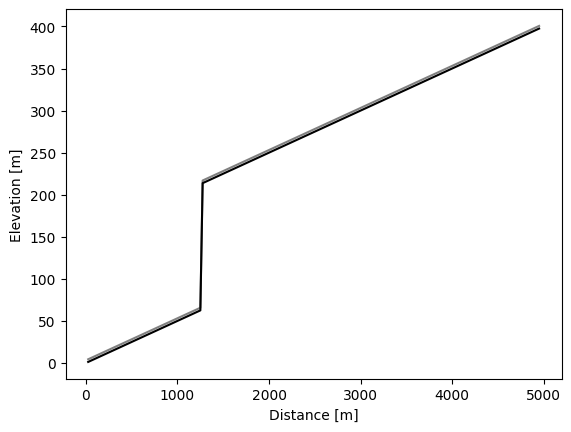

In [10]:
init_profile = np.copy(grid1.at_node['topographic__elevation'][grid1.core_nodes])
init_bedrock_profile = np.copy(grid1.at_node['bedrock__elevation'][grid1.core_nodes])
init_soil_profile = np.copy(grid1.at_node['soil__depth'][grid1.core_nodes])
xvec = np.cumsum(np.ones_like(init_profile)*spacing)
fig,ax = plt.subplots()
ax.plot(xvec, init_profile,color='gray')
ax.plot(xvec, init_bedrock_profile, color='black')
ax.set_xlabel('Distance [m]')
ax.set_ylabel('Elevation [m]')
plt.show()

To associate the landslide with diffrent properties of the grains, we will create additional fields `landslide_size_fraction1` and `landslide_size_fraction2`. These variable will let SoilGrading knows what are the sizes of the grains associate with the slide. For `grid1`,  we set the first size class fraction as `1` which means that the landslide is associate only with the smaller grain size (1 cm). For `grid2` we set the larger size fraction as `1` which means that the landslide is associate only with the coarser grains (7 cm). 

In [11]:
landslide_size_fraction1 = np.zeros_like(grid1.at_node['bed_grains__proportions'])
landslide_size_fraction1[:,0]=1

landslide_size_fraction2 = np.zeros_like(grid2.at_node['bed_grains__proportions'])
landslide_size_fraction2[:,1]=1

Let's run BedrockLandslider 50 years forward.
As the river is associated with an unstable knickpoint, landslides will be initiated by BedrockLandslider and their sediments will be deposited downslope. We will use `SoilGrading` procedure `update_mass_based_on_outsource_dz` to update the `grains__weight` field according to the the landslide deposited and the grain size distribution we created.

In [12]:
for _ in range(50):
    fa1.run_one_step()
    hy1.run_one_step(dt=1)
    sg1.update_mass_based_on_outsource_dz(proportions=landslide_size_fraction1)
    
    
    fa2.run_one_step()
    hy2.run_one_step(dt=1)
    sg2.update_mass_based_on_outsource_dz(proportions=landslide_size_fraction2)

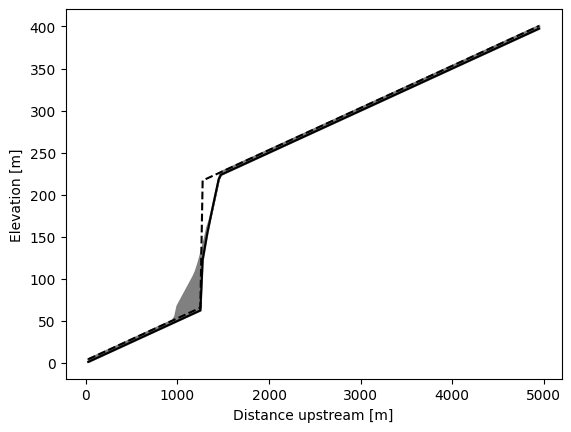

In [13]:
xspace = np.sqrt(grid1.area_of_cell)
xvec = np.cumsum(np.ones_like([grid1.core_nodes])*xspace)

fig,ax = plt.subplots()
ax.plot(xvec,
        grid1.at_node['topographic__elevation'][grid1.core_nodes],
        color='gray')
ax.plot(xvec,
        grid1.at_node['bedrock__elevation'][grid1.core_nodes],
        color='black')

ax.fill_between(xvec, grid1.at_node['topographic__elevation'][grid1.core_nodes], 
                grid1.at_node['bedrock__elevation'][grid1.core_nodes],
               color='gray')

ax.plot(xvec,
        init_profile,color='black',
        ls='--',
        label='Initial profile')

ax.set_xlabel('Distance upstream [m]')
ax.set_ylabel('Elevation [m]')
plt.show()

We will now let EGBE evolove the river profiles over 1200 years and interact with the landslide deposits

In [14]:
timestep=100
n_steps = 12
for i in range(n_steps):
    fa1.run_one_step()
    eroder1.run_one_step(timestep)

    fa2.run_one_step()
    eroder2.run_one_step(timestep)
    if np.mod(i,4)==0:
        print(np.round((i/n_steps)*100,1), '% completed')

0.0 % completed
33.3 % completed
66.7 % completed


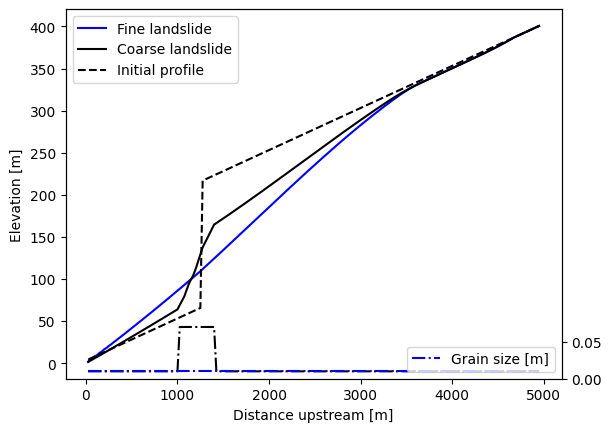

In [15]:
xspace = np.sqrt(grid1.area_of_cell)
xvec = np.cumsum(np.ones_like([grid1.core_nodes])*xspace)

fig,ax = plt.subplots()
ax.plot(xvec,
        grid1.at_node['topographic__elevation'][grid1.core_nodes],
        color='blue',
        label='Fine landslide')
ax.plot(xvec,
        grid2.at_node['topographic__elevation'][grid2.core_nodes],
        color='black',
        label='Coarse landslide')
ax.plot(xvec,
        init_profile,color='black',
        ls='--',
        label='Initial profile')
plt.legend()

# ax.set_xlim([0,3500])
# ax.set_ylim([0,350])

ax2 = ax.twinx()
ax2.plot(xvec, 
         grid2.at_node['median_size__weight'][grid2.core_nodes],
         color='black',ls='-.')

ax2.plot(xvec, 
         grid1.at_node['median_size__weight'][grid1.core_nodes],
        color='blue',ls='-.',
        label='Grain size [m]')
plt.legend(loc='lower right')

ax2.set_yticks([0.0, 0.05])
ax2.set_ylim([0,0.5])
ax.set_xlabel('Distance upstream [m]')
ax.set_ylabel('Elevation [m]')
plt.show()

Differences in the size of the landslide deposits impact the erosion rate and morphology of the rivers. While the coarser landslide slows down incision, the fine landslide washed away and is not distinctly shown in the river profile. 